# 5.9 회귀 실습 - 자전거 대여 수요 예측 

## 데이터 클렌징 및 가공과 데이터 시각화

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

bike_df= pd.read_csv('./bike_train.csv')
print(bike_df.shape)
bike_df.head()

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [2]:
bike_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  str    
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 1.2 MB


In [3]:
#문자열을 datetime 타입으로 변경 
bike_df['datetime']=bike_df.datetime.apply(pd.to_datetime)

#datetime 타입에서 년 원, 일, 시간 추출 
bike_df['year']= bike_df.datetime.apply(lambda x: x.year)
bike_df['month']= bike_df.datetime.apply(lambda x: x.month)
bike_df['day']= bike_df.datetime.apply(lambda x: x.day)
bike_df['hour']= bike_df.datetime.apply(lambda x: x.hour)
bike_df.head(3)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2


In [4]:
drop_columns=['datetime', 'casual', 'registered']
bike_df.drop(drop_columns, axis=1, inplace=True)

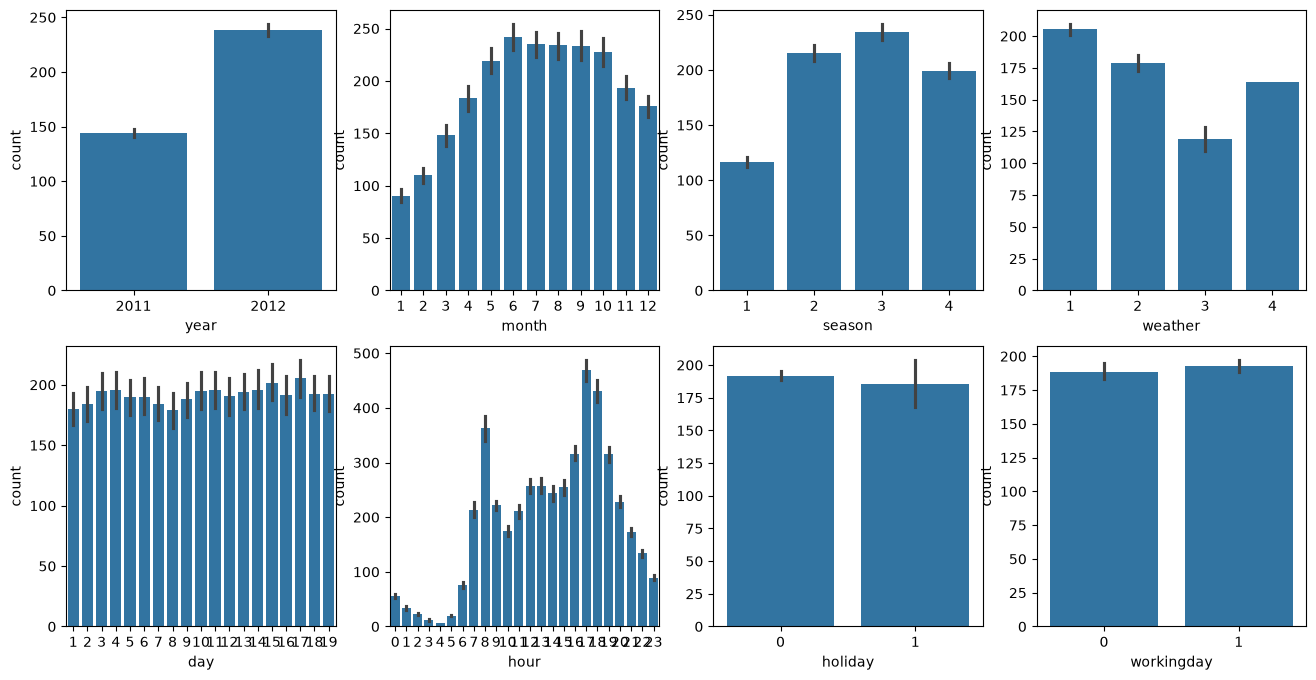

In [5]:
fig, axs= plt.subplots(figsize=(16,8), ncols=4, nrows=2)
cat_features= ['year', 'month', 'season', 'weather', 'day', 'hour', 'holiday', 'workingday']

#cat_features에 있는 모든 칼럼별로 개별 칼럼값에 따른 count 합을 barplot으로 시각화
for i, feature in enumerate(cat_features):
    row= int(i/4)
    col=i%4
    #시본의 barplot을 이용해 칼럼값에 따른 count의 합을 표현 
    sns.barplot(x=feature, y='count', data=bike_df, ax=axs[row][col])

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

#log1p()를 이용해 RMLE 계산 (실제값과 예측값에 로그를 취한 뒤, 그 차이를 제곱하고 평균 내어 제곱근을 취한 평가 지표)
def rmsle(y, pred):
    log_y= np.log1p(y)
    log_pred= np.log1p(pred)
    squared_error= (log_y- log_pred)**2 #제곱합
    rmsle= np.sqrt(np.mean(squared_error)) #제곱합의 평균= msle. 제곱합의 평균에 루트= rmsle
    return rmsle

#사이킷런의 mean_square_error()를 이용해 RMSE 계산 
def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred)) 

def evaluate_regr(y, pred):
    rmsle_val= rmsle(y, pred)
    rmse_val= rmse(y, pred)
    #MAE는 사이킷런의 mean_absolute_error()로 계산 
    mae_val= mean_absolute_error(y, pred)
    print('RMSLE: {0:.3f}, RMSE: {1:.3F}, MAE: {2:.3F}'.format(rmsle_val, rmse_val, mae_val))
                    

## 로그 변환, 피처 인코딩과 모델 학습/예측/평가

In [7]:
#회귀 적용전 : Target값이 정규분포로 되어있는지, 카테고리형 회귀모델의 경우 원-핫 인코딩으로 피처를 인코딩하기 필요함 
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

y_target= bike_df['count']
X_features= bike_df.drop(['count'], axis=1, inplace=False)

X_train, X_test, y_train, y_test= train_test_split(X_features, y_target, test_size=0.3, random_state=0)

lr_reg= LinearRegression()
lr_reg.fit(X_train, y_train)
pred= lr_reg.predict(X_test)

evaluate_regr(y_test, pred)
#예측 오류로서는 비교적 큰 가뵤이 나온다. 

RMSLE: 1.165, RMSE: 140.900, MAE: 105.924


In [8]:
#실제 값과 예측값이 어느 정도 차이가 나는지, DataFrame의 칼럼으로 만들어서 오류 값이 가장 큰 순을 5개 확인하는 함수 
def get_top_error_data(y_test, pred, n_tops=5):
    #DataFrame의 칼럼으로 실제 대여 횟수(count)와 예측값을 서로 비교할 수 있도록 생성. 
    result_df= pd.DataFrame(y_test.values, columns=['real_count'])
    result_df['predicted_count']= np.round(pred)
    result_df['diff']= np.abs(result_df['real_count']-result_df['predicted_count'])

    #차이가 가장 큰 데이터 순으로 출력 
    print(result_df.sort_values('diff', ascending=False)[:n_tops])

get_top_error_data(y_test, pred, n_tops=5)


      real_count  predicted_count   diff
1618         890            322.0  568.0
966          884            327.0  557.0
3151         798            241.0  557.0
412          745            194.0  551.0
2817         856            310.0  546.0


<Axes: >

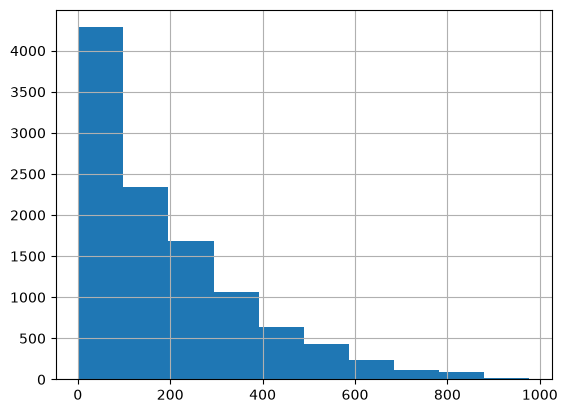

In [9]:
#예측 오류가 큰것을 위에서 확인함. -> Target값의 분포가 왜곡된 형태를 이루고 있을까? 확인 
y_target.hist()
#히스토그램으로 살펴보니, 치우친 형태임. 


<Axes: >

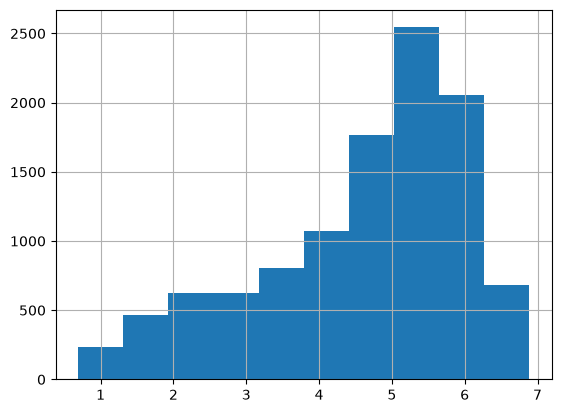

In [10]:
#target 값을 로그 변환. 
#변환된 target값으로 학습하고, 예측한 값은 다시 expm1() 함수를 적용해 원래 scale 값으로 원상복구 필요함
y_log_transform= np.log1p(y_target)
y_log_transform.hist()

#약간 치우쳤지만, 개선됨. 

In [11]:
#다시 학습, 평가 수행하기 
#타깃 칼럼인 count값을 log1p로 로그 변환 
y_target_log= np.log1p(y_target)

#로그 변환된 y_target_log를 반영해 학습/테스트 데이터 세트 분할 
X_train, X_test, y_train, y_test= train_test_split(X_features, y_target_log, test_size=0.3, random_state=0)

lr_reg= LinearRegression()
lr_reg.fit(X_train, y_train)
pred= lr_reg.predict(X_test)

#테스트 데이터 세트의 Target값은 로그 변환됏으므로 다시 expm1을 이용해 원래 스케일로 변환 
y_test_exp= np.expm1(y_test)

#예측값 역시 로그 변환된 타깃 기반으로 학습돼 예측됐으므로 다시 expm1로 스케일 변환 
pred_exp= np.expm1(pred)

evaluate_regr(y_test_exp, pred_exp)


RMSLE: 1.017, RMSE: 162.594, MAE: 109.286


<Axes: ylabel='None'>

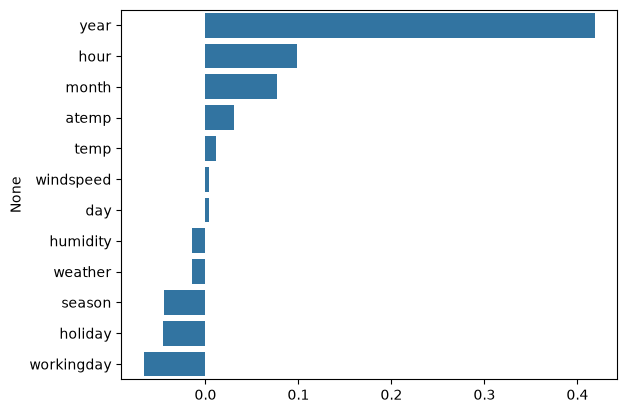

In [12]:
#개별 피처들의 인코딩 적용하기 
#각 피처의 회귀 계숫값을 시각화

coef=pd.Series(lr_reg.coef_, index=X_features.columns)
coef_sort= coef.sort_values(ascending=False)
sns.barplot(x=coef_sort.values, y=coef_sort.index)

In [13]:
#year, month,hour등은 숫자값으로 표현되지만, 카테고리형 피처임. 개별 숫자값의 크기는 의미가 없다. (12월이 11월보다 크게 인식되어서는 안됨)
#선형회귀에서의 카테고리 값: 피처 인토딩에 원-핫 인토딩을 적용해 변환해야함

In [14]:
#year. month. day. hour등의 피처들을 One Hor Encoding
X_features_ohe= pd.get_dummies(X_features, columns= ['year', 'month', 'day', 'hour', 'holiday', 'workingday', 'season', 'weather'])

In [15]:
#원-핫 인코딩이 적용된 피처 데이터 세트 기반으로 데이터세트 분할 
X_train, X_test, y_train, y_test= train_test_split(X_features_ohe, y_target_log, test_size=0.3, random_state=0)

#모델과 학습/테스트 데이터 세트를 입력하면 성능 평가 수치를 반환하는 함수 
def get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=False):
    model.fit(X_train, y_train)
    pred= model.predict(X_test)
    
    if is_expm1 :
        y_test= np.expm1(y_test)
        pred= np.expm1(pred)
    print('###', model.__class__.__name__, '###')
    evaluate_regr(y_test, pred)
#end of function get_model_predict

#모델별로 평가 수행 
lr_reg=LinearRegression()
ridge_reg=Ridge(alpha=10)
lasso_reg= Lasso(alpha=0.01)

for model in [lr_reg, ridge_reg, lasso_reg]:
    get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=True)


### LinearRegression ###
RMSLE: 0.590, RMSE: 97.688, MAE: 63.382
### Ridge ###
RMSLE: 0.590, RMSE: 98.529, MAE: 63.893
### Lasso ###
RMSLE: 0.635, RMSE: 113.219, MAE: 72.803


<Axes: ylabel='None'>

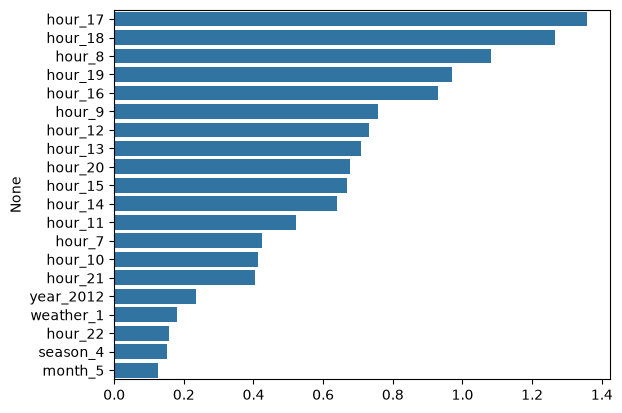

In [16]:
#원-핫 인코딩으로 피처가 늘어났으므로 회귀계수 상위 20개 피처 추출 
coef=pd.Series(lr_reg.coef_, index=X_features_ohe.columns)
coef_sort= coef.sort_values(ascending=False)[:20]
sns.barplot(x=coef_sort.values, y=coef_sort.index)

#원-핫 인코딩을 통해서 피처들의 영향도가 달라진것을 확인 가능. 

In [17]:
#회귀 트리를 이용해 회귀예측 수행- 로그변환된 타겟값, 인코딩된 피처데이터 세트 그대로 이용

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 랜덤 포레스트, GBM, XGBoost, LightGBM model 별로 평가 수행
rf_reg = RandomForestRegressor(n_estimators=500)
gbm_reg = GradientBoostingRegressor(n_estimators=500)
xgb_reg = XGBRegressor(n_estimators=500)
lgbm_reg = LGBMRegressor(n_estimators=500)

for model in [rf_reg, gbm_reg, xgb_reg, lgbm_reg]:
    #XGBoost의 경우 Dataframe이 입력될 경우 버전에 따라 오류 발생 가능. 따라서 ndarray로 변환필요 
    get_model_predict(model, X_train.values, X_test.values, y_train.values, y_test.values, is_expm1=True)

### RandomForestRegressor ###
RMSLE: 0.355, RMSE: 50.148, MAE: 31.134
### GradientBoostingRegressor ###
RMSLE: 0.330, RMSE: 53.346, MAE: 32.749
### XGBRegressor ###
RMSLE: 0.339, RMSE: 51.475, MAE: 31.357
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000327 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 348
[LightGBM] [Info] Number of data points in the train set: 7620, number of used features: 72
[LightGBM] [Info] Start training from score 4.582043
### LGBMRegressor ###
RMSLE: 0.319, RMSE: 47.215, MAE: 29.029


# 5.10 회귀 실습 - 캐글 주택 가격: 고급 회귀 기법 

## 데이터 사전처리

In [18]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

house_df_org= pd.read_csv('house_price.csv')
house_df= house_df_org.copy()
house_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [19]:
print('데이터 세트의 Shape:', house_df.shape)
print('\n전체 피처의 type \n', house_df.dtypes.value_counts())
isnull_series= house_df.isnull().sum()
print('\nNull 칼럼과 그 건수:\n', isnull_series[isnull_series>0].sort_values(ascending=False))

데이터 세트의 Shape: (1460, 81)

전체 피처의 type 
 str        43
int64      35
float64     3
Name: count, dtype: int64

Null 칼럼과 그 건수:
 PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


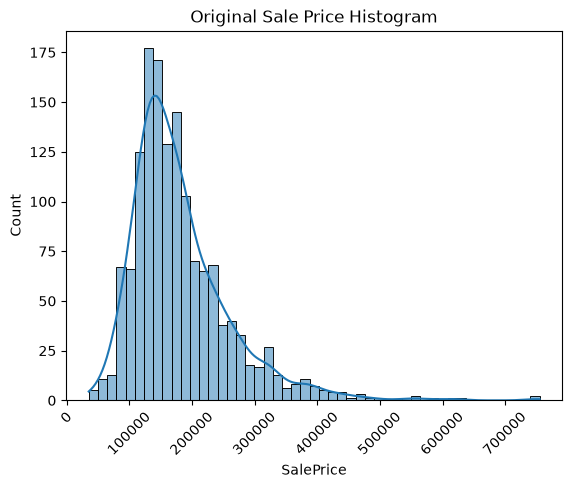

In [20]:

house_df= house_df_org.copy()
plt.title('Original Sale Price Histogram')
plt.xticks(rotation=45)
sns.histplot(house_df['SalePrice'], kde=True)
plt.show()


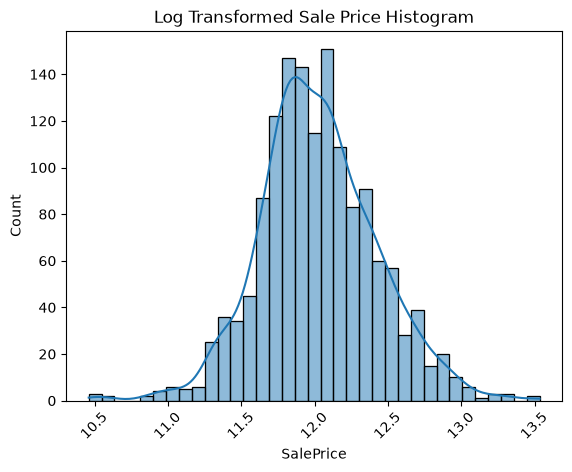

In [21]:
plt.title('Log Transformed Sale Price Histogram')
log_SalePrice= np.log1p(house_df['SalePrice'])
plt.xticks(rotation=45)
sns.histplot(log_SalePrice, kde=True)
plt.show()


In [22]:
#Salesprice 로그 변환
house_df= house_df_org.copy()
original_SalePrice= house_df['SalePrice']
house_df['SalePrice']=np.log1p(house_df['SalePrice'])

#Null 이 너무 많은 컬럼, 단순식별자 칼럼 삭제 
#house_df.drop(['Id','PoolQC' , 'MiscFeature', 'Alley', 'Fence','FireplaceQu'], axis=1 , inplace=True)

#드롭하지 않은 숫자형 Null 칼ㅇ럼은 평균값으로 대체 
house_df.fillna(house_df.mean(numeric_only=True), inplace=True)

#NUll값이 있는 피처명과 타입을 추출 
null_column_count= house_df.isnull().sum()[house_df.isnull().sum()>0]
print('## NUll 피처의 Type :\n', house_df.dtypes[null_column_count.index])

#이제 문자형 피터를 제외하고는 Null 값이 없는 상태가 됨. 


## NUll 피처의 Type :
 Alley           str
MasVnrType      str
BsmtQual        str
BsmtCond        str
BsmtExposure    str
BsmtFinType1    str
BsmtFinType2    str
Electrical      str
FireplaceQu     str
GarageType      str
GarageFinish    str
GarageQual      str
GarageCond      str
PoolQC          str
Fence           str
MiscFeature     str
dtype: object


In [23]:
#이제 문자형 피터를 제외하고는 Null 값이 없는 상태가 됨. 
#문자형 피처는 모두 원-핫 인코딩으로 변환. null값이 칼럼으로 올라가면, 그 줄은 모두 0으로 만들어진다. (원래는 한 줄에 하나의 값이 반드시 1임.)

print('get_dummies() 수행 전 데이터 Shape:', house_df.shape)
house_df_ohe = pd.get_dummies(house_df)
print('get_dummies() 수행 후 데이터 Shape:', house_df_ohe.shape) #칼럼의 개수가 당연히 늘어난다. 

null_column_count = house_df_ohe.isnull().sum()[house_df_ohe.isnull().sum() > 0]
print('## Null 피처의 Type :\n', house_df_ohe.dtypes[null_column_count.index]) #null_column_count.index : null 이 남아있는 칼럼의 이름만 추출. 

get_dummies() 수행 전 데이터 Shape: (1460, 81)
get_dummies() 수행 후 데이터 Shape: (1460, 289)
## Null 피처의 Type :
 Series([], dtype: object)


## 선형 회귀 모델 학습/예측/평가

In [24]:
#카겟값을 이미 로그변환했으므로, rmse 적용하면 rmsle가 자동으로 적용됨. 
#rmse 측정하는 함수 생성
def get_rmse(model):
    pred= model.predict(X_test)
    mse= mean_squared_error(y_test, pred)
    rmse= np.sqrt(mse)
    print('{0} 로그 변환된 RMSE: {1}'.format(model.__class__.__name__,np.round(rmse, 3)))
    return rmse

def get_rmses(models):
    rmses=[]
    for model in models:
        rmse= get_rmse(model)
        rmses.append(rmse)
    return rmses


In [25]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target= house_df_ohe['SalePrice']
X_features= house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test= train_test_split(X_features, y_target, test_size=0.2, random_state=156)

#LinearRegression, Lidge, Lasso 학습, 예측, 평가 
lr_reg= LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg=Ridge()
ridge_reg.fit(X_train, y_train)
lasso_reg=Lasso()
lasso_reg.fit(X_train, y_train)

models= [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)


LinearRegression 로그 변환된 RMSE: 0.134
Ridge 로그 변환된 RMSE: 0.13
Lasso 로그 변환된 RMSE: 0.177


[np.float64(0.13377649423548277),
 np.float64(0.13000240336806285),
 np.float64(0.17688509722693233)]

In [26]:
def get_top_bottom_coef(model, n=10):
    #coef_ 속성을 기반으로 Series 객체를 생성. index는 칼럼명. 
    coef= pd.Series(model.coef_, index= X_features.columns)

    #+상위 10개 -하위 10개의 회귀 계수를 추출해 반환
    coef_high= coef.sort_values(ascending=False).head(n)
    coef_low= coef.sort_values(ascending=False).tail(n)
    return coef_high, coef_low

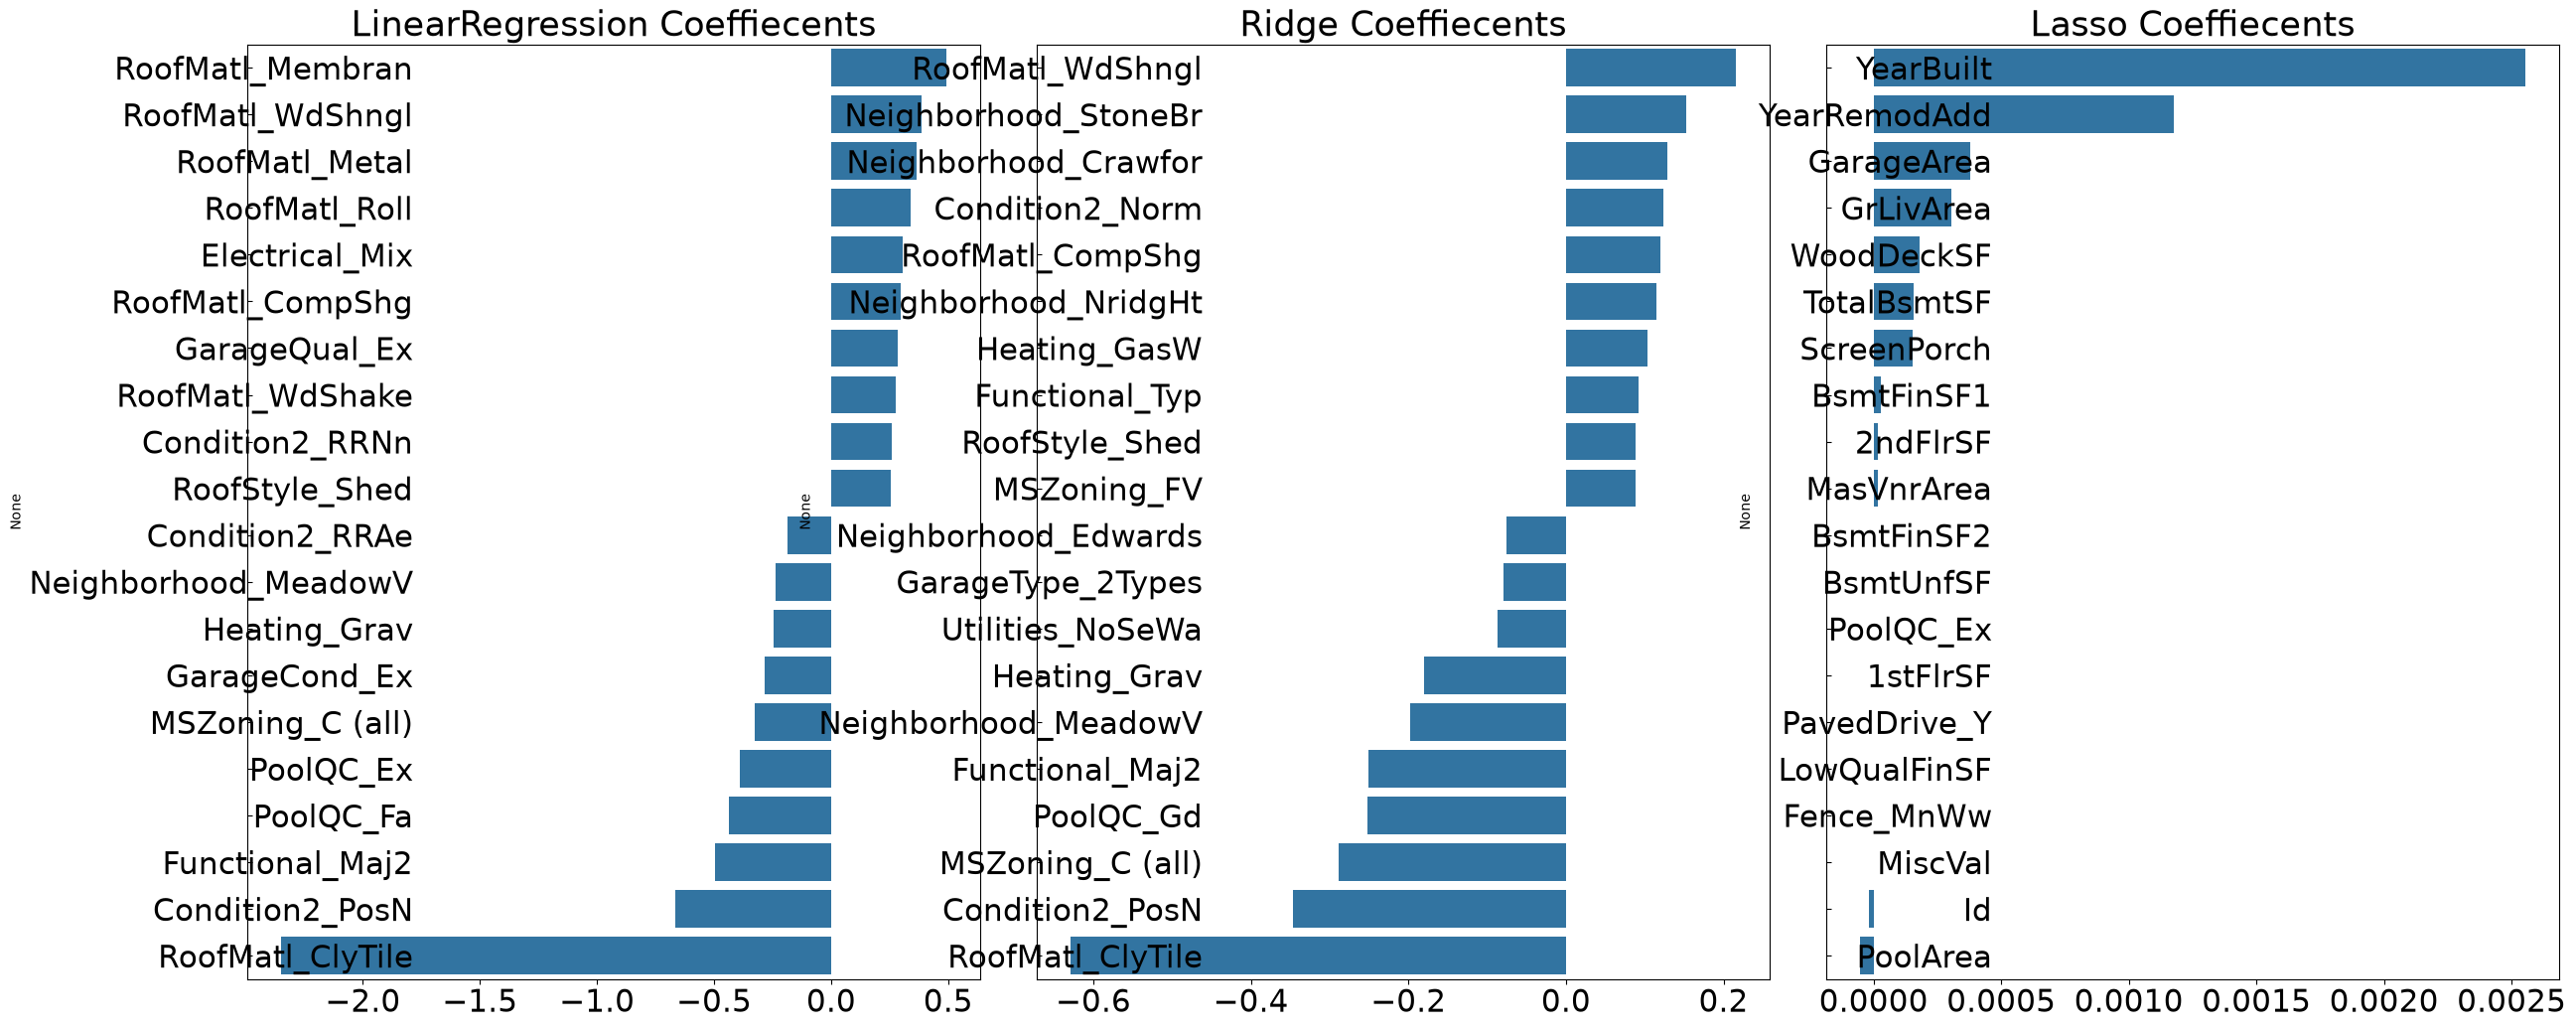

In [27]:
#list 객체로 모델을 입력받아 모델별로 회귀계수 상위 10개, 하위 10개를 추출해 가로 막대 그래프 형태로 출력. 

def visualize_coefficient(models):
    #3개 회귀 모델의 시각화를 위해 3개의 칼럼을 가지는 subplot 생성
    fig, axs= plt.subplots(figsize=(24, 10), nrows=1, ncols=3)
    fig.tight_layout()
    #입력인자로 받은 list 개게인 models에서 차례로 model을 추출해 회귀 계수 시각화 
    for i_num, model in enumerate(models):
        #상위 10개, 하위 10개 회귀 계수를 구하고, 이를 판다스 concat으로 결합 
        coef_high, coef_low= get_top_bottom_coef(model)
        coef_concat= pd.concat([coef_high, coef_low])
        #ax aubplot에 barchar로 표현. 한 화면에 표현하기 위해 tick label 위치와 format 크기 조정 
        axs[i_num].set_title(model.__class__.__name__+' Coeffiecents', size=25)
        axs[i_num].tick_params(axis="y",direction="in", pad=-120)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x=coef_concat.values, y=coef_concat.index , ax=axs[i_num])

#앞 예제에서 학습한 lr_reg, ridge_reg, lasso_reg 모델의 회귀계수 시각화.
models= [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)


In [28]:
#라쏘의 경우에는 전체적으로 회귀계수가 매우 작은데, 그 중에 YearBuilt가 가장 크다. 
#-> 혹시 학습데이터의 데이터 분할에 문제가 있어서 그런것인지, 이번에는 학습과 테스트 데이터세트를 train_test_split으로 분할하지 않고 cross_val_score

from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):

    for model in models:
        #분할하지 않고 전체 데이터로 cross_val_score수행. 모델별 cv rmse깂과 평균 rmse 출력.
        rmse_list= np.sqrt(-cross_val_score(model, X_features, y_target, scoring="neg_mean_squared_error", cv=5))
        rmse_avg= np.mean(rmse_list)
        print('\n{0} CV RMSE 값 리스트: {1}'.format(model.__class__.__name__, np.round(rmse_list, 3)))
        print('\n{0} CV 평균 RMSE 값 : {1}'.format(model.__class__.__name__, np.round(rmse_avg, 3)))


#앞 예제에서 학습한 ridge_reg, lasso_reg 모델의 CV RMSE 값 출력 
models= [ridge_reg, lasso_reg]
get_avg_rmse_cv(models)


Ridge CV RMSE 값 리스트: [0.121 0.154 0.143 0.117 0.189]

Ridge CV 평균 RMSE 값 : 0.145

Lasso CV RMSE 값 리스트: [0.161 0.204 0.177 0.181 0.265]

Lasso CV 평균 RMSE 값 : 0.198


In [29]:
#5개 폴드세트 교차검증도 여전히 라쏘가 릿지에 비해 성능이 떨어진다. 
#릿지, 라쏘 모델에 대해 alpha 파라미터를 변화시키면서 최적값 도출해보기 

#모델과 하이퍼 파라미터 딕셔너리 객체를 받아 최적화 작업의 결과를 표시하는 함수 
from sklearn.model_selection import GridSearchCV

def print_best_params(model, params):
    grid_model= GridSearchCV(model, param_grid=params, scoring='neg_mean_squared_error', cv=5)
    grid_model.fit(X_features, y_target)
    rmse= np.sqrt(-1*grid_model.best_score_)
    print('{0} 5 CV 시 최적 평균 RMSE값 :{1}, 최적 alpha:{2}'.format(model.__class__.__name__, np.round(rmse,4), grid_model.best_params_))

ridge_params= {'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params= {'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10]}
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)


Ridge 5 CV 시 최적 평균 RMSE값 :0.1419, 최적 alpha:{'alpha': 12}
Lasso 5 CV 시 최적 평균 RMSE값 :0.1421, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE: 0.134
Ridge 로그 변환된 RMSE: 0.125
Lasso 로그 변환된 RMSE: 0.121


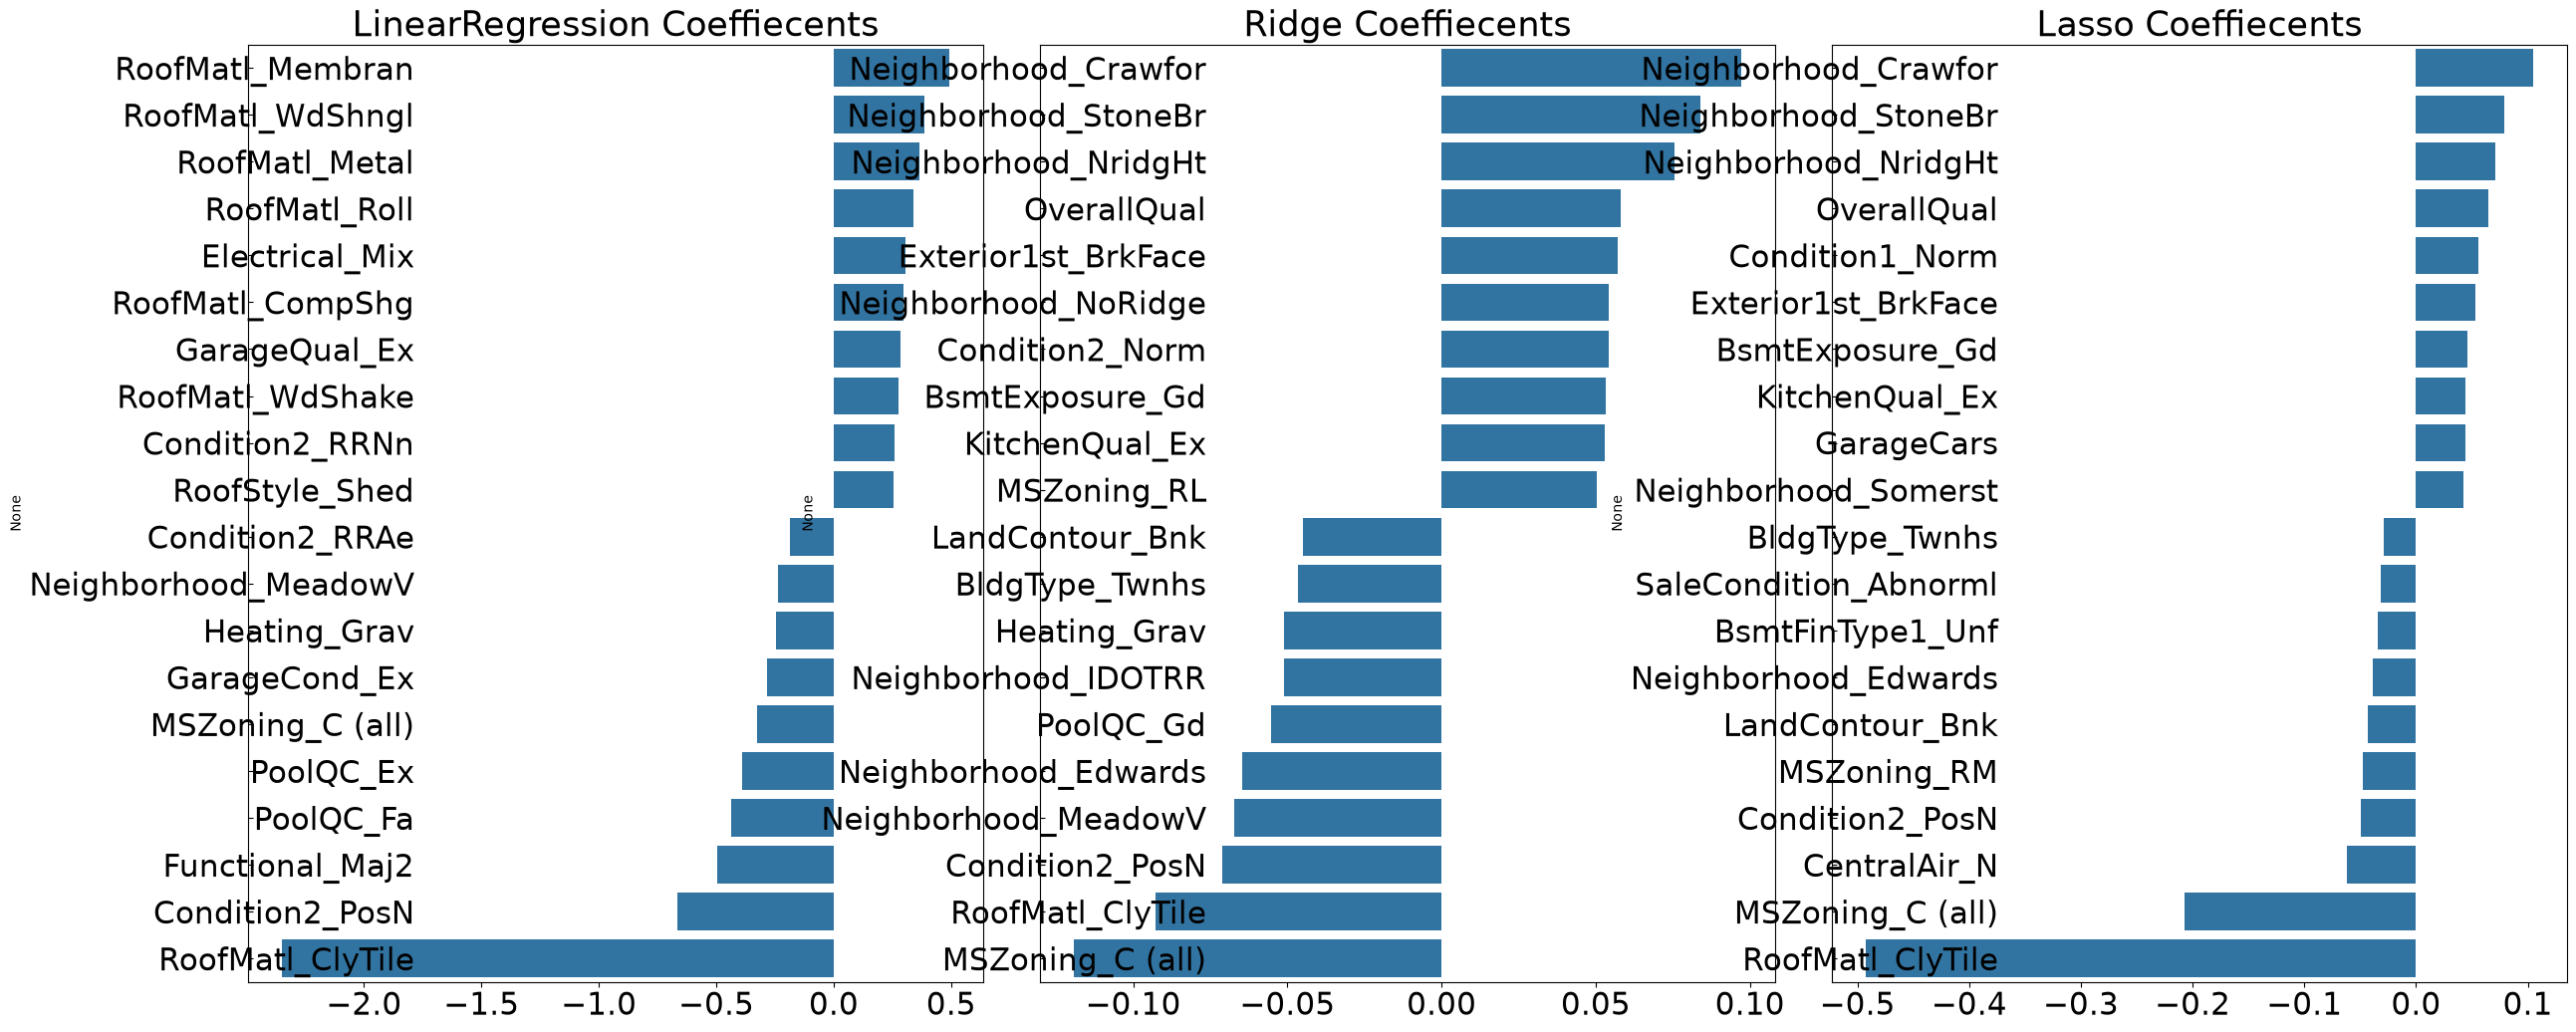

In [30]:
#라쏘 모델의 경우, 최적화 이후 예측성능이 많이 좋아졌음. 
#선형 모델에 최적 alpha값을 설정한 뒤, train_test_split으로 분할된 데이터세트를 이용해 모델의 학습/평가/예측 수행. 모델별 회귀계수 시각화하기 


#앞의 최적화 alpha값으로 학습 데이터로 학습, 테스트 데이터로 예측 및 평가 수행.
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화 
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

#예측성능이 더 좋아짐. 다만 라쏘 모델의 경우 릿지에 비해 계수값이 상당히 작음.


In [31]:
#피처 데이터 세트도 타겟과 마찬가지로, 왜곡된 경우 예측성능을 저하시킬 수 있음. -> 분포 알아보기 
# stats 모듈의 skew() 함수의 반환값이 1이상인 경우를 왜곡정도가 높다고 일반적으로 판단함. -> 여기서는 1이상의 값을 반환하는 피처만 추출해 로그 변환을 적용해서 왜곡정도를 완화해볼 것임.
#원-핫 인코딩이 적용되지 않은 숫자형 피처에 skew() 적용하기. 인코딩된 피처는 당연히 왜곡되었다고 결과가 나오기 떄문(왜곡과는 무관하지만)

from scipy.stats import skew
  #(house_df.dtypes의 인덱스는 칼럼명임.)

#object가 아닌 숫자형 피처의 칼럼 index 객체 추출.
features_index= house_df.dtypes[house_df.dtypes!='str'].index

#house_df에 칼럼 index를 []로 입력하면 해당하는 칼럼 데이터 세트 반환. apply lambda로 skew()호출 
skew_features = house_df[features_index].apply(lambda x : skew(x)) #칼럼별로 왜도가 저장되어있다. 

#skew(왜곡) 정도가 1이상인 칼럼만 추출 
skew_features_top= skew_features[skew_features>1] 
print(skew_features_top.sort_values(ascending=False)) 


MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


In [32]:
#피처 로그변환
house_df[skew_features_top.index]= np.log1p(house_df[skew_features_top.index])

In [33]:
#피처가 일부 로그 변환되었으므로, 다시 원-핫 인코딩을 적용한 df 만들기 -> 다시 분리 
#그 후 최적 alpha값과 rmse 출력 

#왜곡 정도가 높은 피처를 로그 변환했으므로 다시 원-핫 인코딩을 적용하고 피처/타깃 데이터 세트 생성
house_df_ohe= pd.get_dummies(house_df)
y_target= house_df_ohe['SalePrice']
X_features=house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

#피처를 로그 변환한 후 다시 최적 하이퍼 파라미터와 rmse 출력 
ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1,5, 10] }
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE값 :0.1281, 최적 alpha:{'alpha': 12}
Lasso 5 CV 시 최적 평균 RMSE값 :0.1254, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE: 0.13
Ridge 로그 변환된 RMSE: 0.124
Lasso 로그 변환된 RMSE: 0.12


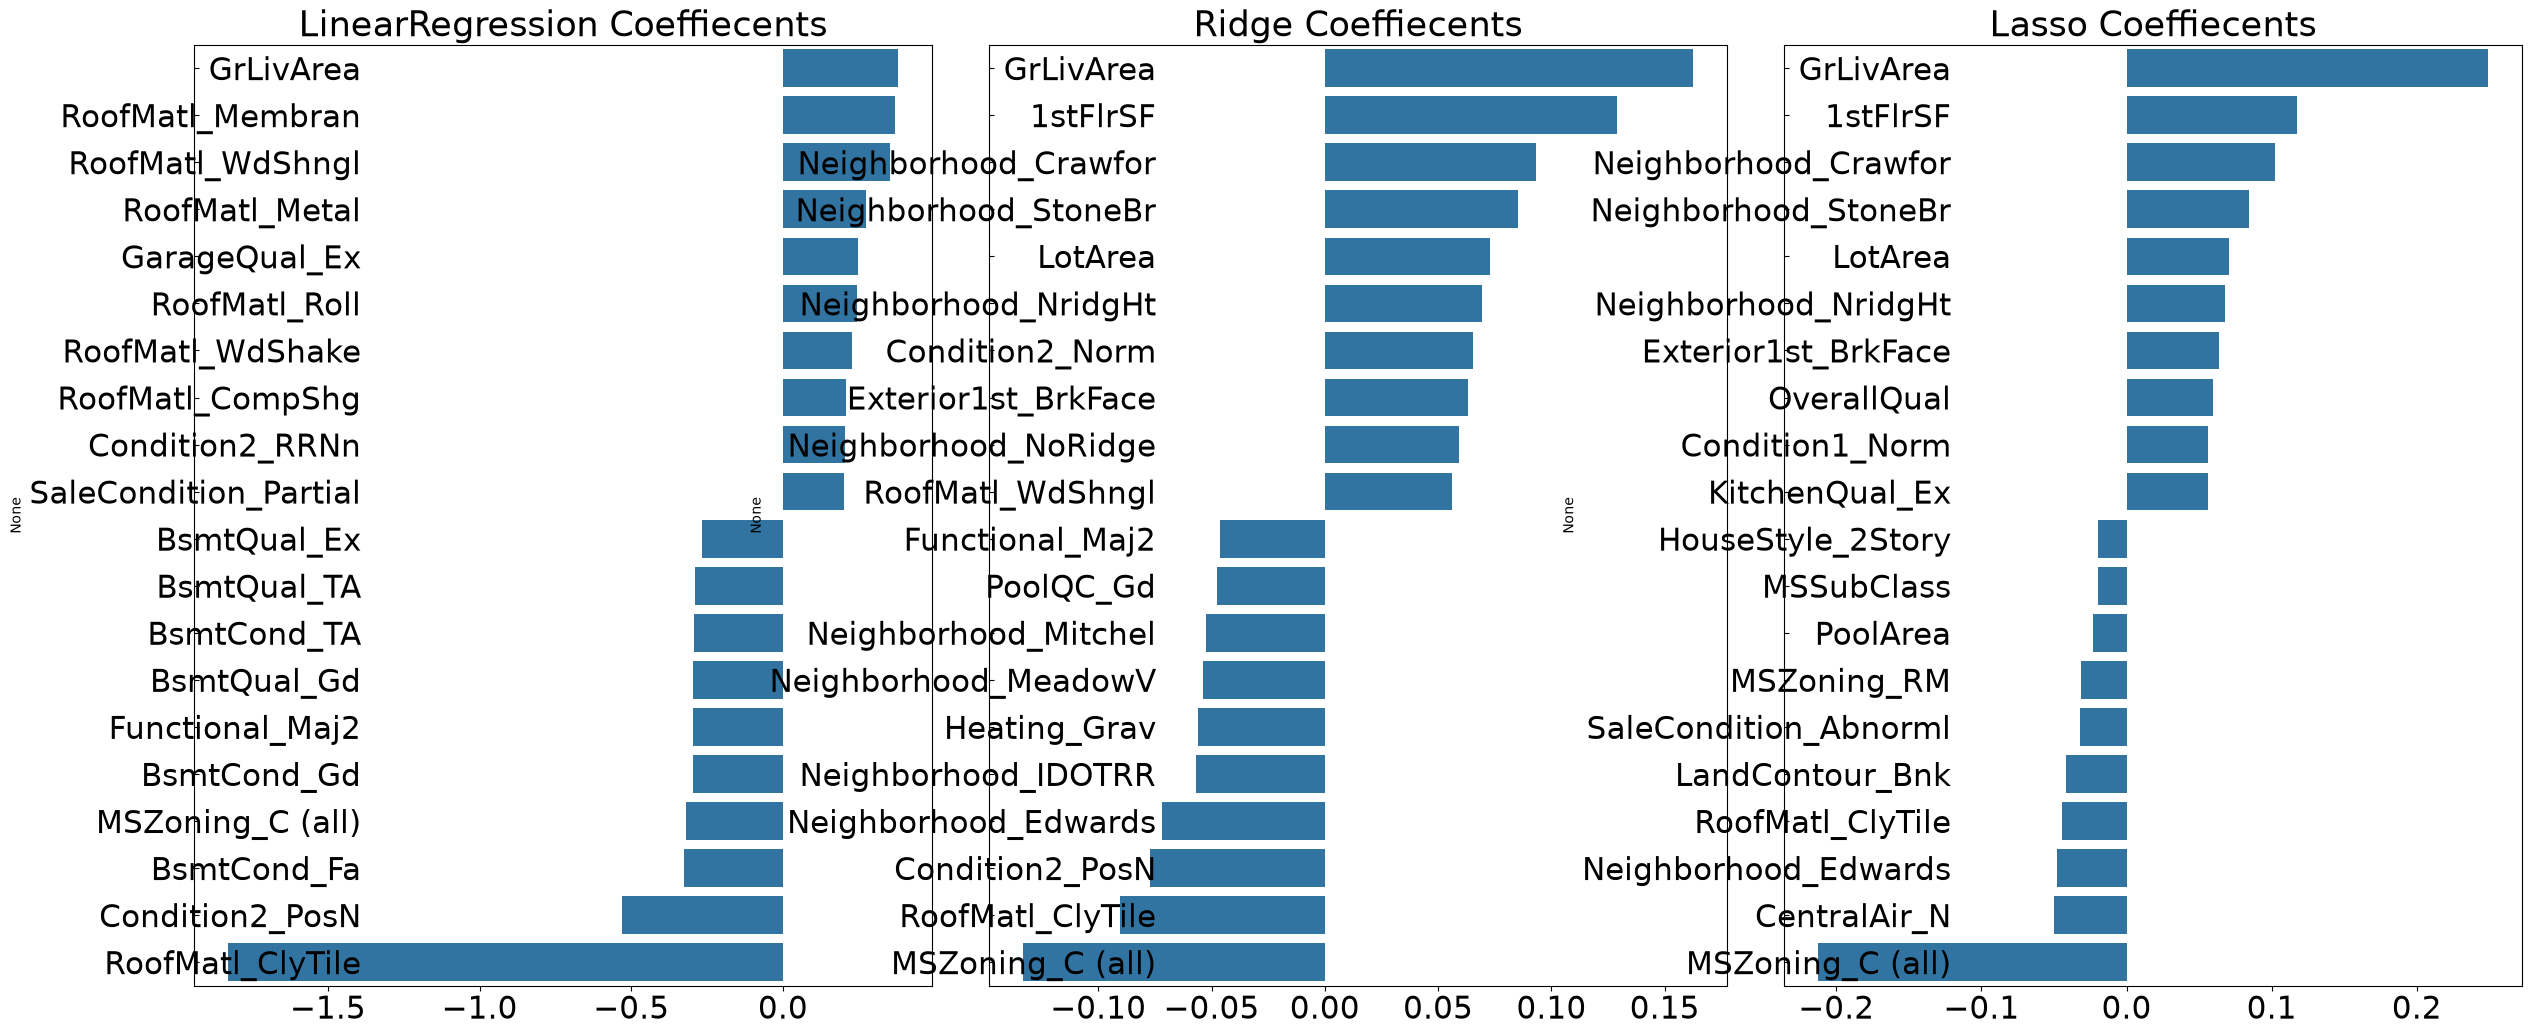

In [34]:
#릿지의 경우 최적 alpha값이 12에서 10으로 변경. 두 모델 모두 rmse 값 향상. 

# 앞의 최적화 alpha값으로 학습데이터로 학습, 테스트 데이터로 예측 및 평가 수행. 
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화 
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

#세 모델 모두 주거 공간의 크기가 회귀계수가 가장 높은 피처가 됨. -> 드디어 원하는 결과가 도출..

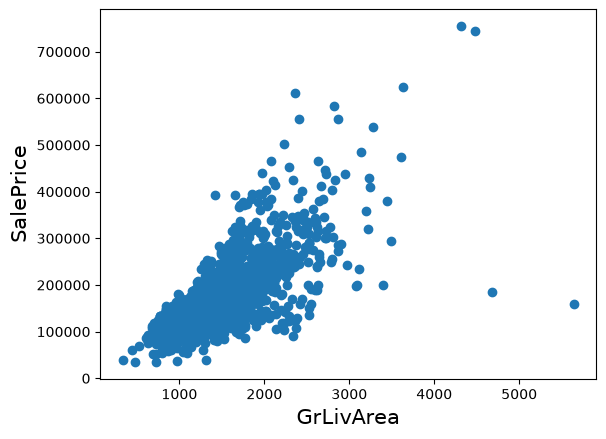

In [35]:
#회귀 계수가 높은 피처의 이상치 데이터 처리 중요.

plt.scatter(x=house_df_org['GrLivArea'], y=house_df_org['SalePrice'])
plt.ylabel('SalePrice', fontsize=15)
plt.xlabel('GrLivArea', fontsize=15)
plt.show() #이상치로 보이는 점 두개 존재. 주거공간이 넓은 데에 비해 가격이 너무 낮다. 

In [36]:
#로그변환이 완료된 house_df_ohe에서 조건 생성 


#cond1 = house_df_ohe['GrLivArea'] > np.log1p(4000)
#cond2 = house_df_ohe['SalePrice'] < np.log1p(500000)

cond1 = house_df_org['GrLivArea'] > 4000
cond2 = house_df_org['SalePrice'] < 500000
outlier_index = house_df_ohe[cond1 & cond2].index

print('아웃라이어 레코드 index :', outlier_index.values)
print('아웃라이어 삭제 전 house_df_ohe shape:', house_df_ohe.shape)

# DataFrame의 index를 이용하여 아웃라이어 레코드 삭제. 
house_df_ohe.drop(outlier_index , axis=0, inplace=True)
print('아웃라이어 삭제 후 house_df_ohe shape:', house_df_ohe.shape)



아웃라이어 레코드 index : [ 523 1298]
아웃라이어 삭제 전 house_df_ohe shape: (1460, 289)
아웃라이어 삭제 후 house_df_ohe shape: (1458, 289)


In [37]:
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice',axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1,5, 10] }
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE값 :0.1135, 최적 alpha:{'alpha': 8}
Lasso 5 CV 시 최적 평균 RMSE값 :0.1124, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE: 0.143
Ridge 로그 변환된 RMSE: 0.104
Lasso 로그 변환된 RMSE: 0.1


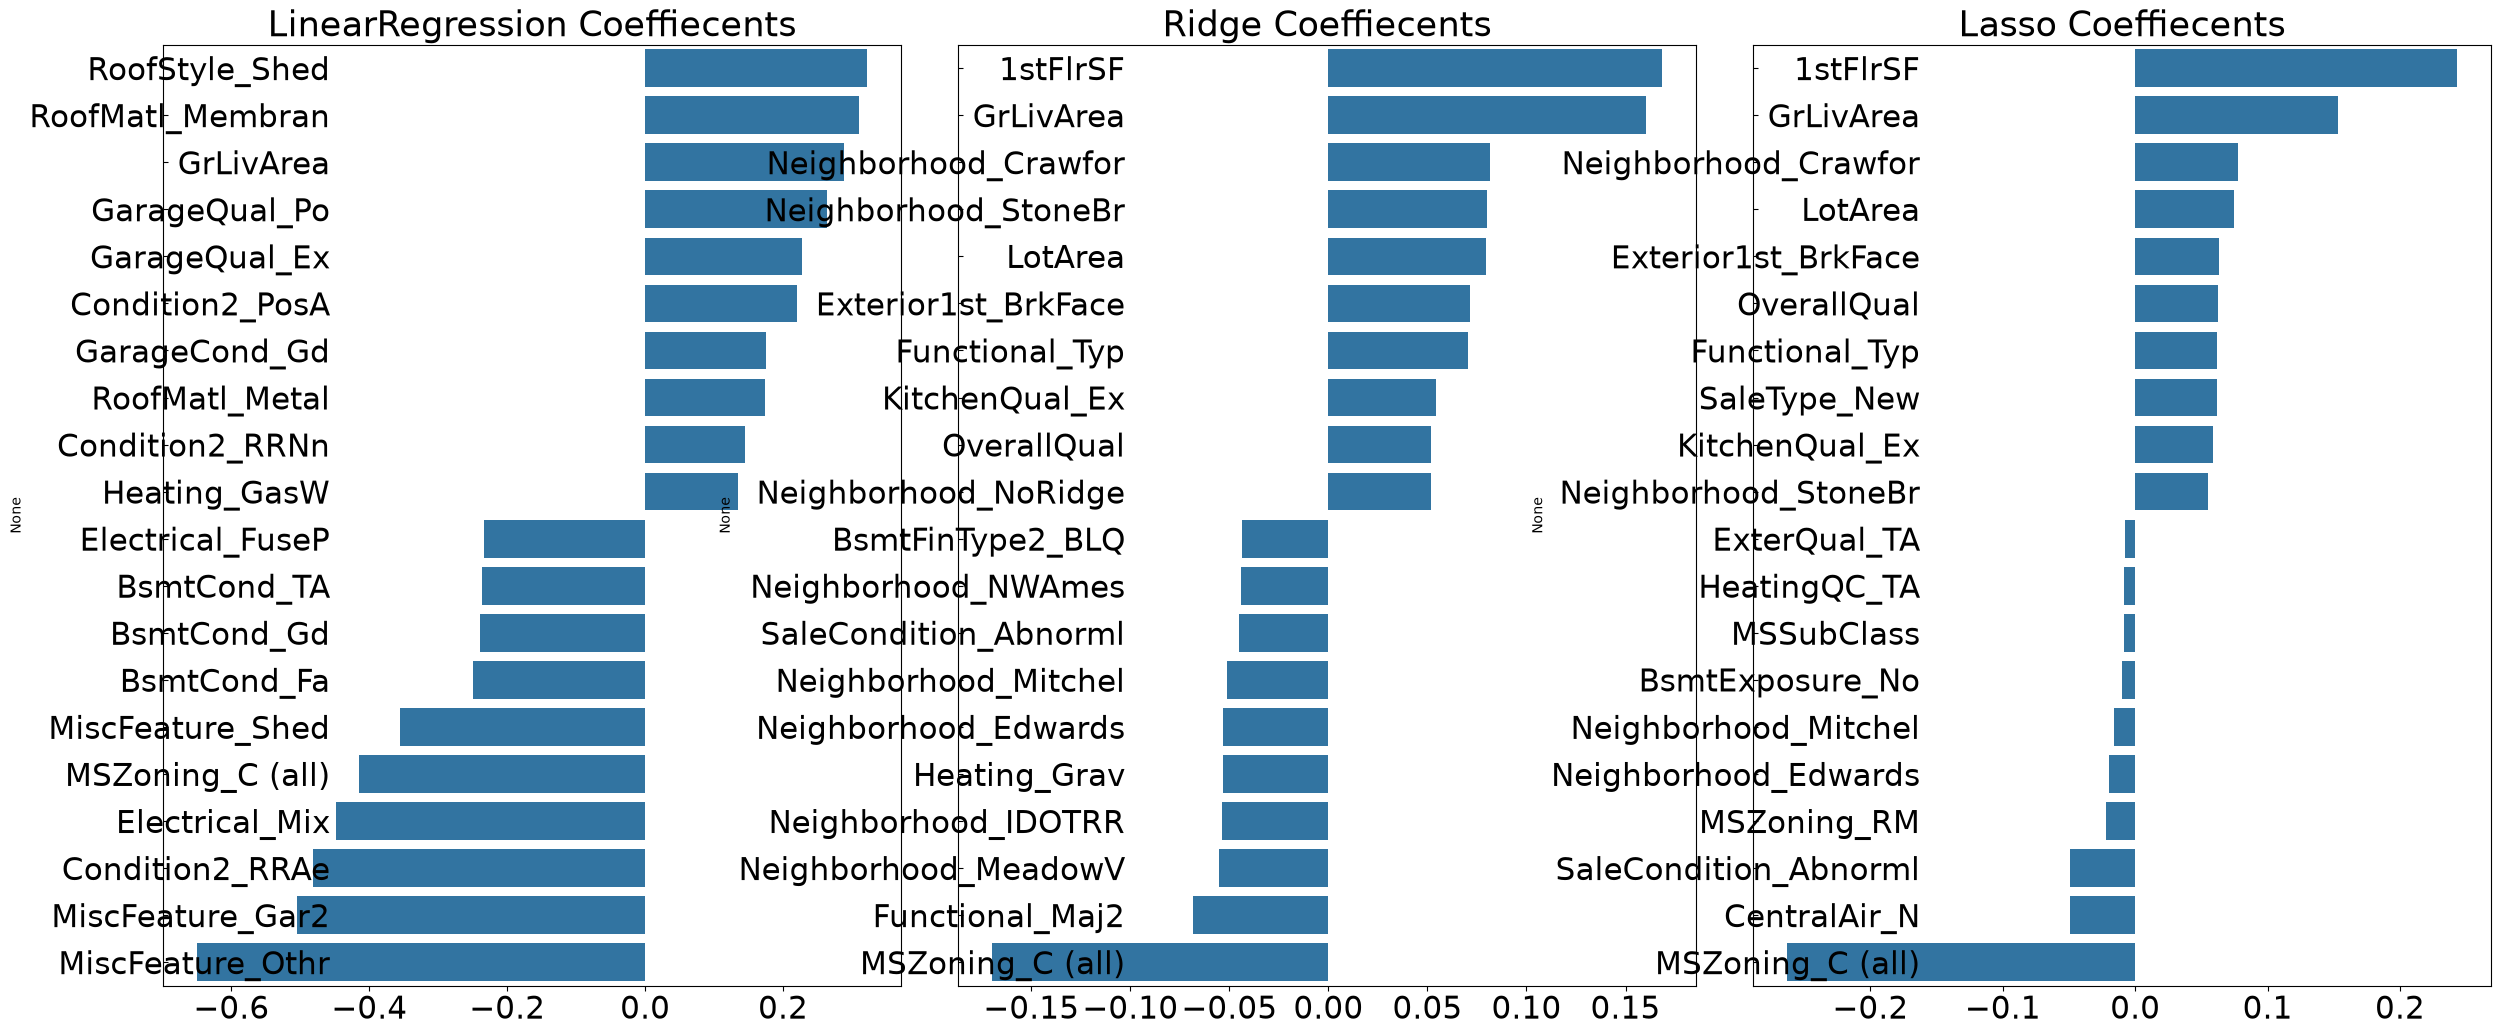

In [39]:
# 앞의 최적화 alpha값으로 학습데이터로 학습, 테스트 데이터로 예측 및 평가 수행. 
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화 
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

## 회귀 트리 모델 학습/예측/평가

In [46]:
from xgboost import XGBRegressor

xgb_params={'n_estimators':[1000]}
xgb_reg= XGBRegressor(n_estimators=1000, learning_rate=0.05, colsample_bytree=0.5, subsample=0.8)
best_xgb=print_best_params(xgb_reg, xgb_params)

XGBRegressor 5 CV 시 최적 평균 RMSE값 :0.1194, 최적 alpha:{'n_estimators': 1000}


In [47]:
from lightgbm import LGBMRegressor

lgbm_params= {'n_estimators':[1000]}
lgbm_reg= LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4, subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)
best_lgbm=print_best_params(lgbm_reg, lgbm_params)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002717 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3430
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 182
[LightGBM] [Info] Start training from score 12.021352
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001859 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3440
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 178
[LightGBM] [Info] Start training from score 12.023516
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of 

In [45]:
def print_best_params(model, params):
    grid_model= GridSearchCV(model, param_grid=params, scoring='neg_mean_squared_error', cv=5)
    grid_model.fit(X_features, y_target)
    rmse= np.sqrt(-1*grid_model.best_score_)
    print('{0} 5 CV 시 최적 평균 RMSE값 :{1}, 최적 alpha:{2}'.format(model.__class__.__name__, np.round(rmse,4), grid_model.best_params_))
    return grid_model.best_estimator_

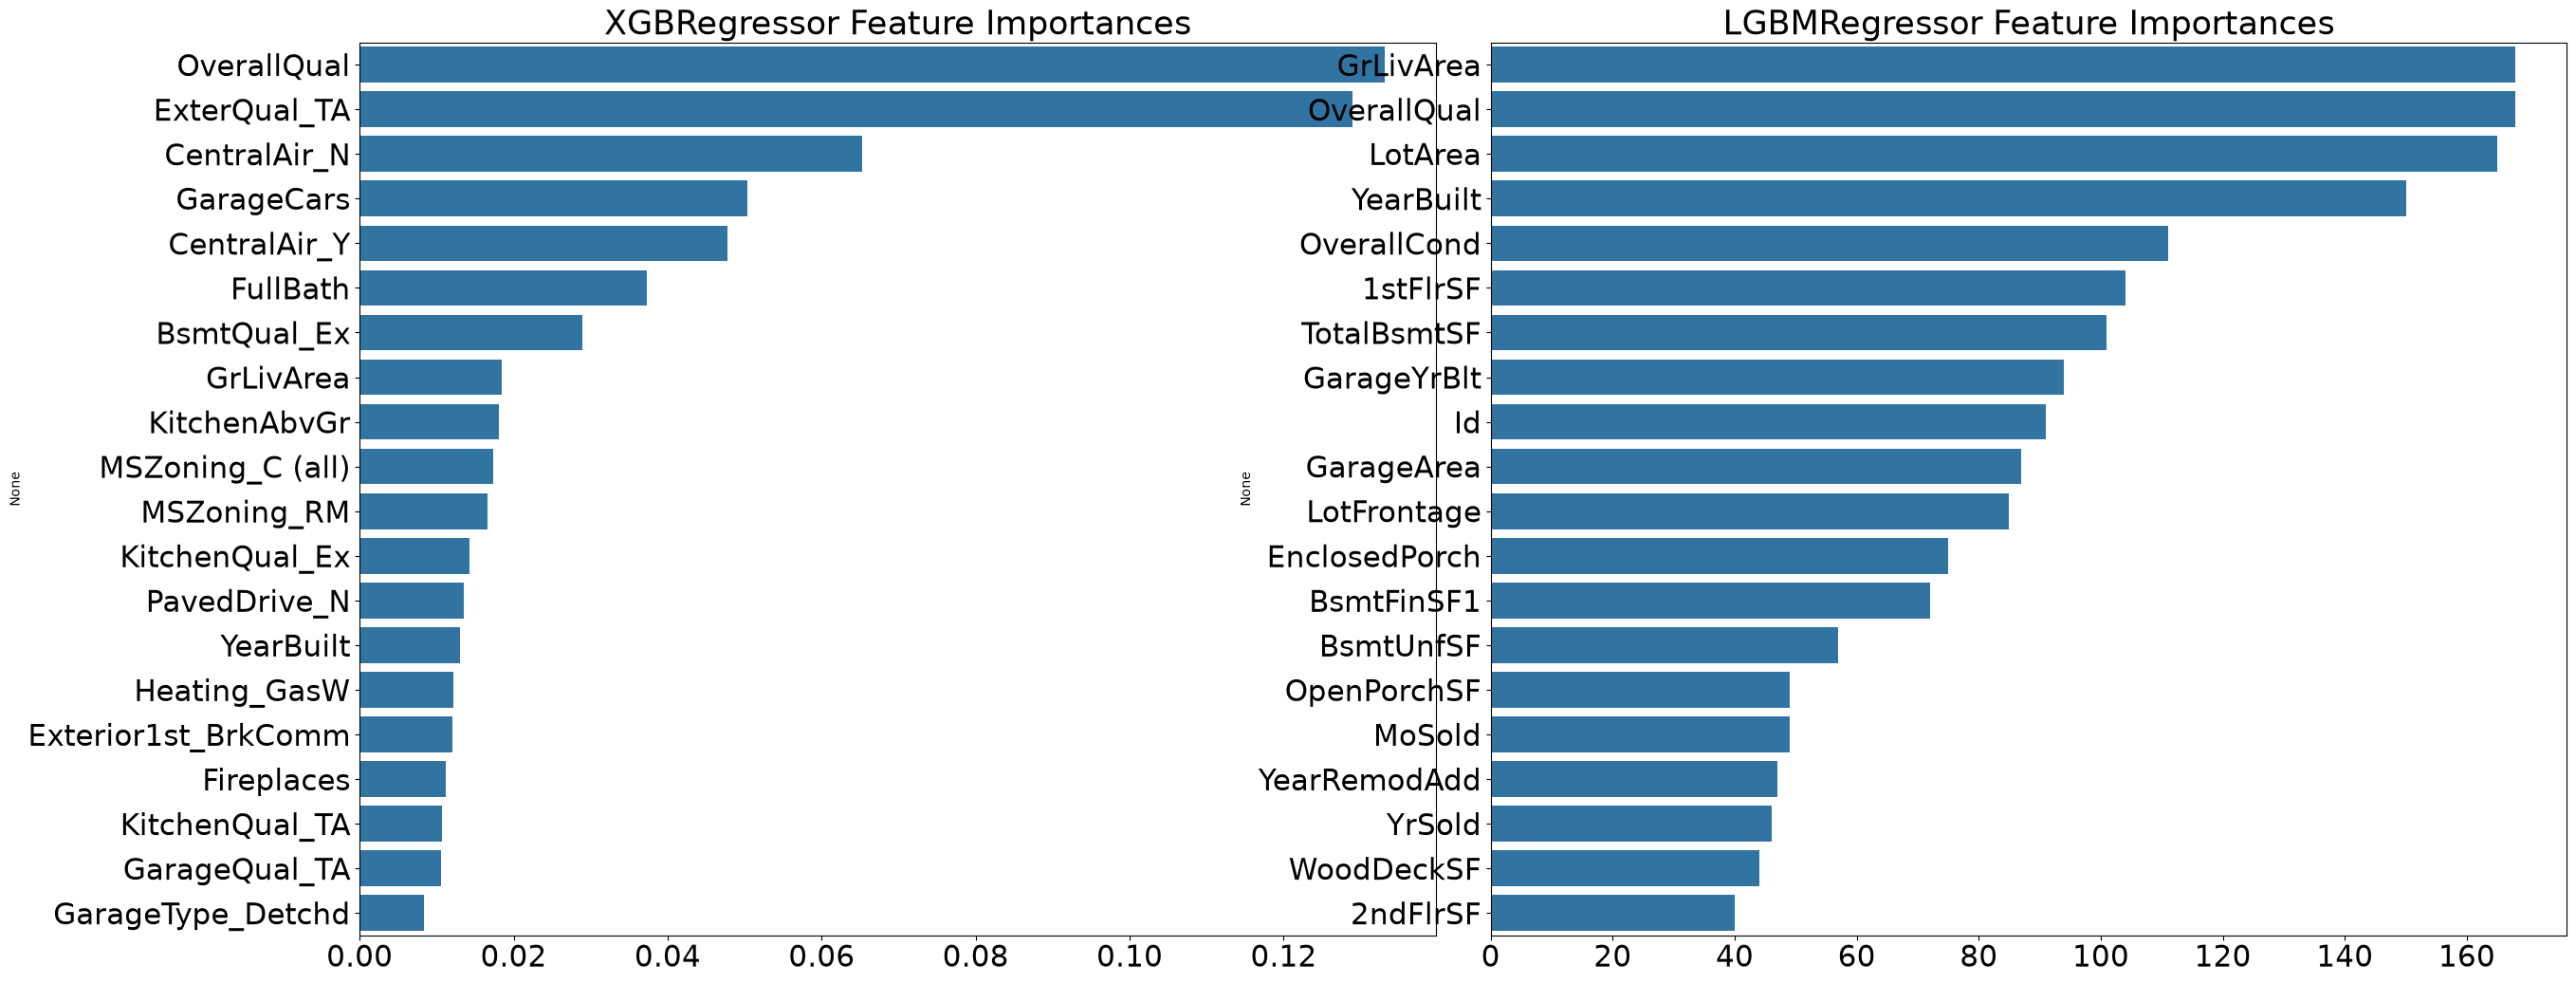

In [48]:
# 모델의 중요도 상위 20개의 피처명과 그때의 중요도값을 Series로 반환.
def get_top_features(model):
    ftr_importances_values = model.feature_importances_
    ftr_importances = pd.Series(ftr_importances_values, index=X_features.columns)
    ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
    return ftr_top20

def visualize_ftr_importances(models):
    # 2개 회귀 모델의 시각화를 위해 2개의 컬럼을 가지는 subplot 생성
    fig, axs = plt.subplots(figsize=(24,10),nrows=1, ncols=2)
    fig.tight_layout() 
    # 입력인자로 받은 list객체인 models에서 차례로 model을 추출하여 피처 중요도 시각화. 
    for i_num, model in enumerate(models):
        # 중요도 상위 20개의 피처명과 그때의 중요도값 추출 
        ftr_top20 = get_top_features(model)
        axs[i_num].set_title(model.__class__.__name__+' Feature Importances', size=25)
        #font 크기 조정.
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x=ftr_top20.values, y=ftr_top20.index , ax=axs[i_num])

# print_best_params( )가 반환한 GridSearchCV로 최적화된 모델의 피처 중요도 시각화   
models = [best_xgb, best_lgbm]
visualize_ftr_importances(models)


## 회귀 모델의 예측 결과 혼합을 통한 최종 예측

In [49]:
def get_rmse_pred(preds):
    for key in preds.keys():
        pred_value= preds[key]
        mse= mean_squared_error(y_test, pred_value)
        rmse= np.sqrt(mse)
        print('{0} 모델의 RMSE:{1}'.format(key, rmse))

#개별 모델의 학습
ridge_reg= Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg=Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

#개별 모델 예측
ridge_pred=ridge_reg.predict(X_test)
lasso_pred=lasso_reg.predict(X_test)

#개별 모델 예측값 혼합으로 최종 예측값 도출 
pred= 0.4*ridge_pred+0.6*lasso_pred
preds= {'최종 혼합': pred,
        'Ridge':ridge_pred,
        'Lasso':lasso_pred}

#최종 혼합 모델, 개별 모델의 RMSE 값 출력 
get_rmse_pred(preds)

최종 혼합 모델의 RMSE:0.10018339180961178
Ridge 모델의 RMSE:0.10433090872834011
Lasso 모델의 RMSE:0.10014953372065533


In [ ]:
xgb_reg= XGBRegressor(n_estimators=1000, learning_rate=0.05, colsample_bytree=0.5, subsample=0.8)
lgbm_reg= LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4, subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)

xgb_reg.fit(X_train, y_train)
lgbm_reg.fit(X_train, y_train)
xgb_pred= xgb_reg.predict(X_test)
lgbm_pred= lgbm_reg.predict(X_test)

pred=0.5*xgb_pred + 0.5*lgbm_pred
preds={'최종 혼합': pred,
        'XGBM':xgb_pred,
        'LGBM':lgbm_pred}

get_rmse_pred(preds)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003268 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3449
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 183
[LightGBM] [Info] Start training from score 12.025343
최종 혼합 모델의 RMSE:0.1014964812581632
XGBM 모델의 RMSE:0.10690870409552419
LGBM 모델의 RMSE:0.10384765259102217


## 스태킹 앙상블 모델을 통한 회귀 예측 

In [55]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

#개별 기반 모델에서 최종 메타 모델이 사용할 학습 및 테스트용 데이터를 생성하기 위한 함수.
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):
    #지정된 nfolds 값으로 KFold 생성
    kf= KFold(n_splits=n_folds, shuffle=False)

    #추후에 메타 모델이 사용할 학습 데이터 반환을 위한 넘파이 배열 초기화
    train_fold_pred= np.zeros((X_train_n.shape[0],1))
    test_pred=np.zeros((X_test_n.shape[0], n_folds))
    print(model.__class__.__name__, 'model 시작')

    for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n)): #학습용 데이터 인덱스의 1차원 array, 검증용 데이터 인덱스의 1차원 array 를 튜플로 묶어서 반환. 
        #입력된 학습데이터에서 기반 모델이 학습/예측할 폴드 데이터 세트 추출
        print('\t 폴드 세트:', folder_counter, '시작')
        X_tr= X_train_n[train_index]
        y_tr= y_train_n[train_index]
        X_te= X_train_n[valid_index]

        #폴드 세트 내부에서 다시 만들어진 학습 데이터로 기반 모델의 학습 수행 
        model.fit(X_tr, y_tr)

        #폴드 세트 내부에서 다시 만들어진 검증 데이터로 기반 모델 예측 후 데이터 저장.
        train_fold_pred[valid_index, :]= model.predict(X_te).reshape(-1, 1)

        #입력된 원본 테스트 데이터를 폴드 세트 내 학습된 기반 모델에서 예측 후 데이터 저장.
        test_pred[:, folder_counter]=model.predict(X_test_n)

    #폴드 세트 내에서 원본 테스트 데이터를 예측한 데이터를 평균하여 테스트 데이터로 생성
    test_pred_mean= np.mean(test_pred, axis=1).reshape(-1, 1)

    #train_fold_pred는 최종 메타 모델이 사용하는 학습 데이터. test_pred_mean은 테스트 데이터 
    return train_fold_pred, test_pred_mean 


In [56]:
# get_stacking_base_datasets()는 넘파이 ndarray를 인자로 사용하므로 DataFrame을 넘파이로 변환.
X_train_n= X_train.values
X_test_n= X_test.values
y_train_n= y_train.values

#각 개별 기반(Base) 모델이 생성한 학습용/테스트용 데이터 반환.
ridge_train, ridge_test= get_stacking_base_datasets(ridge_reg, X_train_n, y_train_n, X_test_n, 5)
lasso_train, lasso_test= get_stacking_base_datasets(lasso_reg, X_train_n, y_train_n, X_test_n, 5)
xgb_train, xgb_test= get_stacking_base_datasets(xgb_reg, X_train_n, y_train_n, X_test_n, 5)
lgbm_train, lgbm_test= get_stacking_base_datasets(lgbm_reg, X_train_n, y_train_n, X_test_n, 5)



Ridge model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
Lasso model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
XGBRegressor model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
LGBMRegressor model 시작
	 폴드 세트: 0 시작
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011760 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3197
[LightGBM] [Info] Number of data points in the train set: 932, number of used features: 166
[LightGBM] [Info] Start training from score 12.035561
	 폴드 세트: 1 시작
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013876 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3224
[LightGBM] [Info] Number of data points in the train set: 933, number of used feature

In [58]:
#개별 모델이 반환한 학습 및 테스트용 데이터 세트를 스태킹 형태로 결합.
Stack_final_X_train= np.concatenate((ridge_train, lasso_train, xgb_train, lgbm_train), axis=1)
Stack_final_X_test= np.concatenate((ridge_test, lasso_test, xgb_test, lgbm_test), axis=1)

#최종 메타 모델은 라쏘 모델을 적용.
meta_model_lasso= Lasso(alpha=0.0005)

#개별 모델 예측값을 기반으로 새롭게 만들어진 학습/테스트 데이터로 메타 모델 예측 및 RMSE 측정.
meta_model_lasso.fit(Stack_final_X_train, y_train)
final= meta_model_lasso.predict(Stack_final_X_test)
mse= mean_squared_error(y_test, final)
rmse= np.sqrt(mse)
print('스태킹 회귀 모델의 최종 RMSE 값은:', rmse)


스태킹 회귀 모델의 최종 RMSE 값은: 0.09756402544680064
